# SYNTHETIC SOFTWARE TEST — NOT ASSIGNMENT FINDINGS

All rows and all results in this notebook are fictional and only demonstrate software behavior. Use Healthcare_Insurance_Analysis.ipynb for the assigned Kaggle CSV.

# Healthcare Insurance Cost Analysis
**Unit 1 — Data Analytics and Python for Data Preparation**  
Level 4 Diploma | Tasks 1–4 | deadline 4 December 2026

**Learner:** Add your name and candidate number after reviewing the work.

**Evidence map:** 1.1/1.2 Business case below; 2.1/2.3 ETL and EDA; 2.2 code review and validation; 3.1/3.2 AI evidence and storytelling; 3.3 evaluation; 4.1/4.2 data governance and lineage. See `README.md` for dashboard deployment and final checks. This is an AI-assisted project; the learner must validate the assigned file and be able to explain each decision.

# Task 1 — Business case (1.1, 1.2)

## 1.1 Applications of healthcare insurance analytics
The audience is the fictional insurer's finance/planning team, operations leads and managers. These applications are researched possibilities, not results from the assigned CSV. AHRQ's Medical Expenditure Panel Survey (MEPS) illustrates the value of expenditure, utilization, coverage and demographic data [1]. CMS's electronic clinical quality measurement resources illustrate the additional structured clinical information required to measure quality [2].

| Application | Method and data | Management decision and example | Benefit and limitation |
|---|---|---|---|
| Expense comparison | Group and summarize recorded charges by smoking, age band and region; mean, median, IQR, counts. This CSV supports these comparisons. | Finance can prioritize groups for further investigation and create sample-based expense scenarios. | Transparent and low cost; skew and unequal group sizes can mislead; no causal or temporal inference. |
| Population grouping and resource planning | Descriptive segmentation by age bands and smoking. For actual staffing, additionally need enrollment counts, visits, service type, dates and capacity. | Operations could investigate whether outreach or staffing demand varies across groups. | Makes planning granular; sample composition is not enrollment or utilization, and small groups are unstable. |
| Expense estimation | Regression or other predictive methods need historical charges, service dates, coverage, diagnoses and prior claims. | Finance could forecast aggregate expenditure and compare a model against a median or mean baseline. | May improve forecasts after out-of-sample evaluation; distribution drift, confounding and leakage can invalidate results. This CSV lacks time information, so it cannot validate a future-period forecast. |
| Treatment effectiveness / quality | Compare outcomes, risk-adjusted readmission rates or quality measures using diagnoses, interventions, baseline risk, follow-up and outcome definitions [2]. | A clinical quality lead could investigate whether a care pathway is associated with fewer readmissions. | Supports quality improvement, but needs clinical data and study design to address selection bias. This CSV cannot evaluate treatment effectiveness. |

## 1.2 Planning problem and opportunity
Managers need to understand variation and uncertainty in recorded medical insurance charges to decide where further expenditure investigation is warranted. They need comprehensible comparisons, counts and transparent limitations, not a black-box pricing tool. Finance needs mean charges and spread for sample-based scenario planning; operations needs age and region segments; governance needs source permissions, reproducibility and appropriate aggregate use.

- BQ1: How do charges differ by smoking status? Compare count, mean, median, spread, box plots and the mean difference. Investigate within age bands.
- BQ2: How are age and BMI associated with charges overall and within smoking groups? Use scatter plots, Pearson correlations and group counts. Avoid treating category codes as quantities.
- BQ3: How do means and medians vary across regions, and do patterns persist within smoking groups? Compare group counts, composition and stratified medians.

A key data challenge is uncertain uniqueness: there is no identifier to establish that equal rows are duplicate people. Another is skew and unobserved clinical confounding. Preserve plausible high charges and matching rows, document exclusions and show both mean and median. Opportunity: a shared dashboard permits managers to compare relevant subgroups without rerunning Python. AI can help review ETL code, detect edge cases and draft narrative wording; a human must check outputs against independently calculated summaries. Future expense estimation could use a train/test split and baseline error comparison, then external/temporal validation on suitable data. Do not use this sample to assign individual prices or make claims about treatment.

References (accessed 25 November 2026): [1] AHRQ, Medical Expenditure Panel Survey, https://www.ahrq.gov/data/meps.html. [2] CMS eCQI, FHIR overview for quality measurement, https://ecqi.healthit.gov/fhir/about. Assigned dataset: https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance (download and licence not verified in this environment).


## Task 2 — Python setup, source inspection and ETL (2.1, 2.3)
Use Python, pandas (tabular operations), NumPy (numerical summaries and reconciliation), and Matplotlib (charts). Install packages from `requirements.txt`. The helper functions in `analysis.py` are shared with the dashboard so the same formulas, rules and charts are used. Inspect those functions as well as this notebook. The notebook is run from the project root; if a schema differs, investigate rather than forcing columns into the assumed schema.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from analysis import (ROOT, RAW, CLEAN, FIELDS, BANDS, CATEGORIES, read_raw, digest,
                      profile, clean_data, load_roundtrip, summary, filter_data,
                      correlations, narrative, chart, read_cleaned)
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| NumPy:', np.__version__, '| Matplotlib:', matplotlib.__version__)
pd.set_option('display.max_columns', 20)

Python: 3.13.5
pandas: 2.2.3 | NumPy: 2.3.5 | Matplotlib: 3.10.8


In [2]:
# Explicit synthetic mode. It never touches the assigned data directory.
DEMO = True
source_path = ROOT / 'examples/synthetic_fixture.csv'
output_path = ROOT / 'examples/generated/synthetic_cleaned.csv'
metadata = {'source_url':'locally generated fictional fixture', 'original_filename':source_path.name,
            'description':'Synthetic software test only; not actual insurance data',
            'currency_or_units':'fictional units', 'coverage':'fictional', 'permission_confirmed':False}
unit = metadata['currency_or_units']
print('SYNTHETIC TEST ONLY — not the Kaggle dataset')
display(pd.Series(metadata, name='value'))

SYNTHETIC TEST ONLY — not the Kaggle dataset


source_url                            locally generated fictional fixture
original_filename                                   synthetic_fixture.csv
description             Synthetic software test only; not actual insur...
currency_or_units                                         fictional units
coverage                                                        fictional
permission_confirmed                                                False
Name: value, dtype: object

### Extract — preserve raw input and profile quality
The hash is a fingerprint of the exact downloaded bytes. It detects changes to the raw file, but does not prove the data are accurate or official. We display row count, examples, data types, missing counts, category values and numerical ranges before applying transformations. The original DataFrame and file are preserved.

In [3]:
raw = read_raw(source_path)
raw_hash = digest(source_path)
raw_snapshot = raw.copy(deep=True)
print('Source file:', source_path.relative_to(ROOT), '| SHA-256:', raw_hash)
print('Actual dimensions (rows, columns):', raw.shape)
display(raw.head())
display(profile(raw))
for col in ['sex','smoker','region']:
    if col in raw: print(col, raw[col].value_counts(dropna=False).to_dict())
display(raw.describe(include='all').T)
print('Exact repeated rows beyond first:', raw.duplicated().sum())

Source file: examples/synthetic_fixture.csv | SHA-256: dda2eecfca65c71379b6a35c64fd86e8c291f85e5805f68e62eae43ee57b4ee4
Actual dimensions (rows, columns): (51, 7)


,age,sex,bmi,children,smoker,region,charges
0,18,female,19.00,0,yes,northeast,12187.00
1,25,male,22.17,1,yes,northwest,13093.61
2,32,female,25.34,2,no,southeast,5000.22
3,39,male,28.51,3,no,southwest,5906.83
4,46,female,31.68,0,no,northeast,6813.44


,dtype,missing,distinct_non_null
age,int64,0,47
sex,object,0,3
bmi,float64,0,49
children,int64,0,4
smoker,object,0,4
region,object,0,5
charges,float64,0,50


sex {'female': 26, 'male': 24, ' female ': 1}
smoker {'no': 28, 'yes': 21, ' YES ': 1, 'unknown': 1}
region {'northeast': 14, 'northwest': 12, 'southeast': 12, 'southwest': 12, 'NORTHEAST': 1}


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,51.0,NaN,NaN,NaN,40.058824,13.901672,18.0,28.5,40.0,51.5,64.0
sex,51,3,female,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,51.0,NaN,NaN,NaN,28.603137,6.282858,19.0,23.025,28.7,33.835,38.97
children,51.0,NaN,NaN,NaN,1.45098,1.119173,0.0,0.5,1.0,2.0,3.0
smoker,51,4,no,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,51,5,northeast,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,51.0,NaN,NaN,NaN,10839.295686,9826.948334,-5.0,5233.86,7916.32,14589.03,70000.0


Exact repeated rows beyond first: 1


### Transform — evidence-based cleaning
Work on a copy. Normalize case and spaces, convert numeric fields, check finite values and valid categories, and quarantine invalid rows with reasons. The adult age bound is a project assumption requiring review if the source covers children. BMI values outside 10–80 are flagged for review, not automatically removed. Keep matching valid rows because a unique person identifier is unavailable. Keep valid high charges: they matter for expense planning. Use a Tukey IQR flag to examine extremes without deleting them. Age bands are left-inclusive and right-exclusive, with 60+ open-ended. Imputation and encoding are unnecessary when there are no missing values or model requirements; missing essential values are quarantined rather than invented. If exclusions are material, investigate potential selection bias and revise rules only with documented evidence.

In [4]:
cleaned, rejected, audit = clean_data(raw)
pd.testing.assert_frame_equal(raw, raw_snapshot)
assert digest(source_path) == raw_hash
print('Before/after rows:', len(raw), '→', len(cleaned), '| excluded:', len(rejected))
display(pd.Series(audit, name='count').to_frame())
display(profile(cleaned))
print('Retained percentage:', round(100*len(cleaned)/len(raw), 2))
if len(rejected):
    display(rejected['reason'].value_counts().rename('count'))
else:
    print('No records failed validation; no imputation or exclusions needed.')
print('Raw null cells:', raw.isna().sum().sum(), '| cleaned null cells:', cleaned.isna().sum().sum())
print('Raw unchanged: verified.')

Before/after rows: 51 → 50 | excluded: 1


,count
raw_rows,51
cleaned_rows,50
excluded_rows,1
raw_exact_repeat_excess,1
cleaned_match_excess_retained,1
charge_iqr_flags_retained,1
bmi_review_flags_retained,0
sex,1
smoker,1
region,1


,dtype,missing,distinct_non_null
age,int64,0,47
sex,string,0,2
bmi,float64,0,49
children,int64,0,4
smoker,string,0,2
region,string,0,4
charges,float64,0,49
age_band,string,0,5


Retained percentage: 98.04


reason
charges_rule; smoker_category    1
Name: count, dtype: int64

Raw null cells: 0 | cleaned null cells: 0
Raw unchanged: verified.


In [5]:
# Inspect potential outliers without automatically removing valid values.
q1, q3 = cleaned.charges.quantile([.25, .75])
iqr = q3 - q1
low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f'IQR: {iqr:,.2f}; lower / upper fences: {low:,.2f} / {high:,.2f}')
print('Valid charges outside fences, retained:', audit['charge_iqr_flags_retained'])
display(cleaned.loc[:, ['age_band','charges']].groupby('age_band').agg(n=('charges','size'), median=('charges','median')))

IQR: 9,336.49; lower / upper fences: -8,654.05 / 28,691.89
Valid charges outside fences, retained: 1


,n,median
age_band,,
18–29,14,8566.87
30–39,10,5233.86
40–49,11,6888.18
50–59,10,12098.52
60+,5,17626.66


### Load — write separate output and verify reload
Round-trip validation checks all values and types. Record the cleaned checksum in the source metadata used by the dashboard. Quarantine stays local; only the cleaned data, with permission, are eligible for deployment.

In [6]:
cleaned = load_roundtrip(cleaned, output_path)
pd.testing.assert_frame_equal(cleaned, read_cleaned(output_path), check_exact=False, rtol=1e-12)
output_path.parent.mkdir(parents=True, exist_ok=True)
(output_path.parent / 'quality_audit.json').write_text(json.dumps(audit, indent=2))
rejected.to_csv(output_path.parent / 'quarantine_local.csv', index=False)
metadata['raw_sha256'] = raw_hash
metadata['cleaned_sha256'] = digest(output_path)
if not DEMO:
    meta_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Validated cleaned CSV:', output_path.relative_to(ROOT))
print('Cleaned SHA-256:', metadata['cleaned_sha256'])
assert len(raw) == len(cleaned) + len(rejected)

Validated cleaned CSV: examples/generated/synthetic_cleaned.csv
Cleaned SHA-256: 1021be01d73c67c1d47fc8e4c59cf4e61d2e7f43044abcb2239c935039e86121


## Exploratory analysis and business questions (2.1, 2.3)
Mean describes arithmetic average and is relevant for expense totals; median describes the middle record and is robust to extreme charges. Sample standard deviation (ddof=1) describes variability; IQR describes the middle half. All amounts use the verified source unit, not an assumed currency. A histogram reveals the shape and potential skew.

,fictional units
n,50.000000
mean,11056.181600
median,8014.455000
sample_sd,9802.639122
min,3383.270000
max,70000.000000
IQR,9336.485000
skewness,4.564837


Mean minus median: 3041.73
Skewness sign: positive (right-skew tendency)


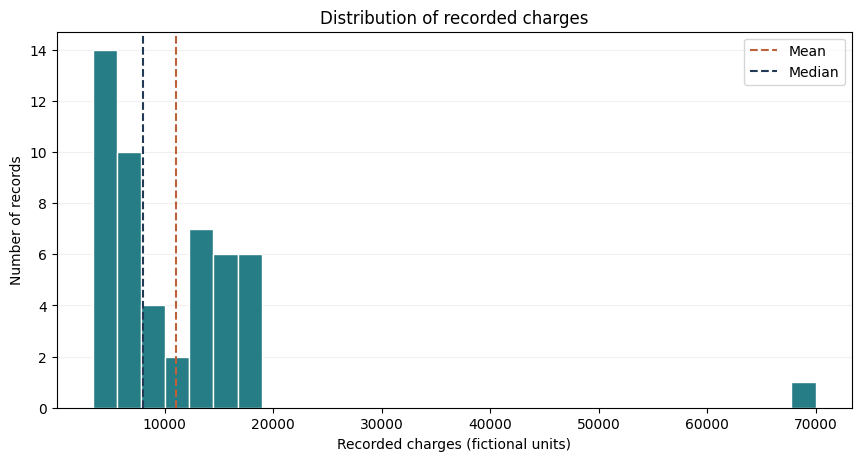

In [7]:
x = cleaned.charges.to_numpy(dtype=float)
overall = pd.Series({'n': x.size, 'mean': np.mean(x), 'median': np.median(x),
                     'sample_sd': np.std(x, ddof=1) if x.size > 1 else np.nan,
                     'min': np.min(x), 'max': np.max(x), 'IQR': iqr,
                     'skewness': cleaned.charges.skew()}, name=unit)
display(overall.to_frame())
assert np.isclose(np.mean(x), cleaned.charges.mean())
assert np.isclose(np.median(x), cleaned.charges.median())
print('Mean minus median:', round(np.mean(x)-np.median(x), 2))
print('Skewness sign:', 'positive (right-skew tendency)' if overall.skewness > 0 else 'negative or zero; inspect histogram')
chart(cleaned, 'histogram', unit); plt.show()

### BQ1 — Smoking groups
Select rows with `.loc` and boolean conditions, group by the readable smoking category, and aggregate charges. Box plots reveal the median, middle half and extremes; group counts contextualize comparisons. Compare age bands as a secondary check; these descriptive comparisons are not adjusted causal effects.

,smoker,n,mean,median,sd,minimum,maximum
0,no,28,5887.73,5747.93,1539.21,3383.27,8822.93
1,yes,22,17634.21,15397.50,11841.45,12187.00,70000.00


,age_band,smoker,n,mean,median,sd,minimum,maximum
0,18–29,no,7,4193.52,4289.88,581.17,3383.27,4946.74
1,18–29,yes,7,13005.85,13093.61,701.41,12187.00,14143.01
2,30–39,no,8,5111.19,5098.35,493.07,4364.62,5906.83
3,30–39,yes,2,14233.86,14233.86,224.72,14074.96,14392.76
4,40–49,no,6,6442.67,6397.50,358.34,5981.57,6888.18
5,40–49,yes,5,26318.00,15691.91,24423.70,14785.30,70000.00
6,50–59,no,5,7725.64,7794.79,345.35,7205.98,8112.59
7,50–59,yes,5,16701.33,16720.05,480.46,16084.45,17308.86
8,60+,no,2,8664.03,8664.03,224.72,8505.13,8822.93
9,60+,yes,3,17782.42,17701.40,208.43,17626.66,18019.20


Smoker minus non-smoker mean: 11,746.48 fictional units
Smoker minus non-smoker median: 9,649.58 fictional units


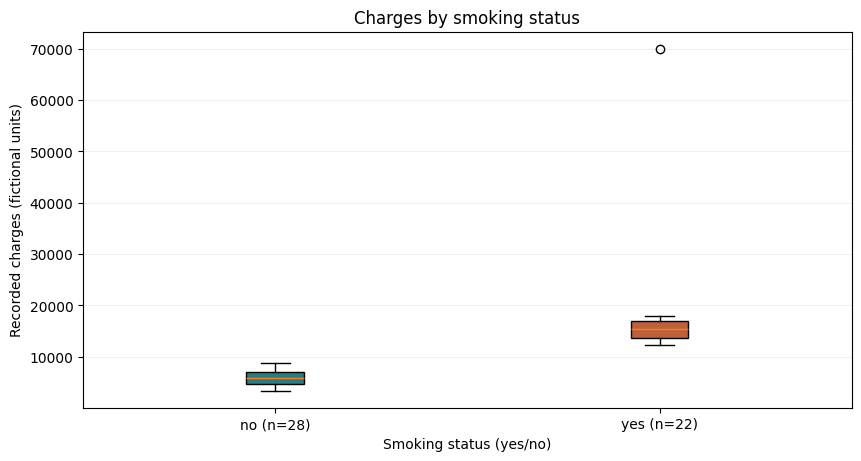

In [8]:
smoking = summary(cleaned, 'smoker')
display(smoking.round(2))
display(summary(cleaned, ['age_band','smoker']).round(2))
assert smoking.n.sum() == len(cleaned)
for key in smoking.smoker:
    selected = cleaned.loc[cleaned.smoker.eq(key), 'charges'].to_numpy()
    reported = smoking.loc[smoking.smoker.eq(key), 'mean'].iloc[0]
    assert np.isclose(sum(selected)/len(selected), reported)
if {'yes','no'}.issubset(set(smoking.smoker)):
    s = smoking.set_index('smoker')
    print(f'Smoker minus non-smoker mean: {s.loc["yes","mean"]-s.loc["no","mean"]:,.2f} {unit}')
    print(f'Smoker minus non-smoker median: {s.loc["yes","median"]-s.loc["no","median"]:,.2f} {unit}')
else:
    print('BQ1 partly answered: only one smoking group is available.')
chart(cleaned, 'smoking', unit); plt.show()

### BQ2 — Age, BMI and charges
A scatter plot retains individual variation that group summaries hide. Pearson's r ranges from -1 to +1 and measures linear association, not causation or necessarily nonlinear patterns. Compare overall and smoking-specific correlations, because pooling groups may obscure different patterns. An undefined correlation occurs when a group is too small or has no variation. Only genuinely numeric fields enter the heatmap.

,group,n,age_r,bmi_r
0,all,50,0.206,0.102
1,no,28,0.961,0.667
2,yes,22,0.133,0.083


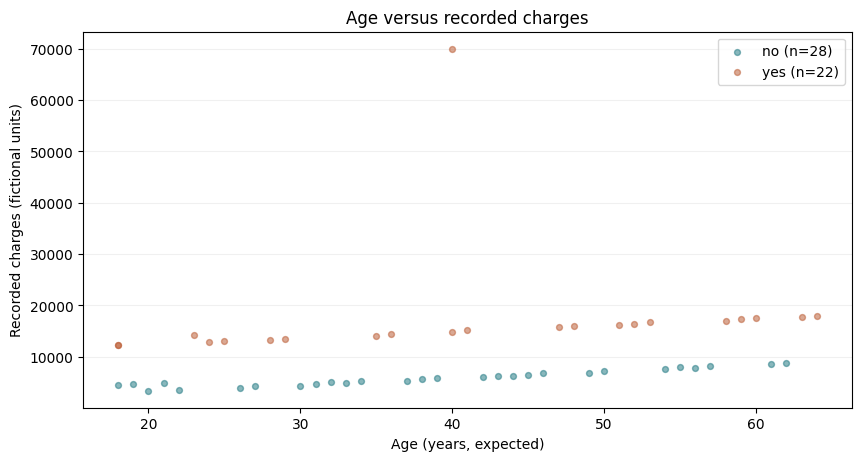

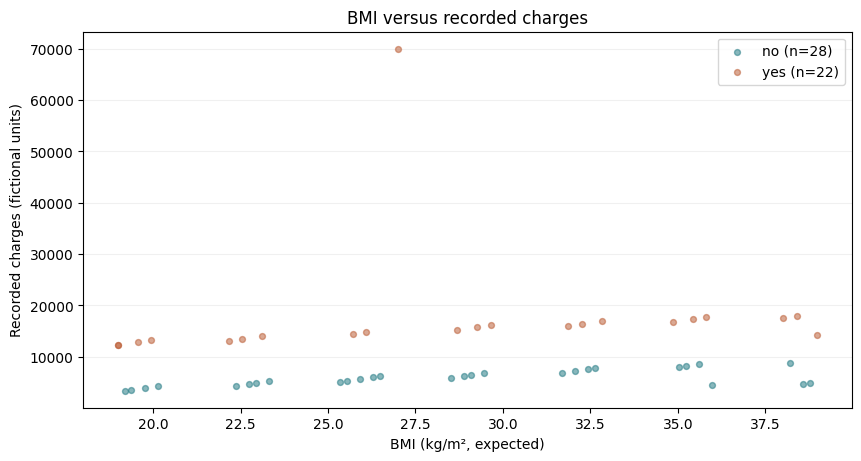

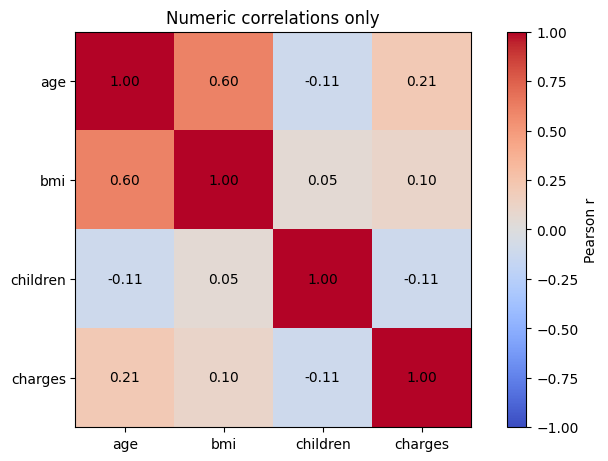

all: n=50; age r=0.206; BMI r=0.102.
no: n=28; age r=0.961; BMI r=0.667.
yes: n=22; age r=0.133; BMI r=0.083.
Interpret these coefficients with scatter plots; no causal effect is established.


In [9]:
corr_table = correlations(cleaned)
display(corr_table.round(3))
for kind in ['age','bmi','heatmap']:
    chart(cleaned, kind, unit); plt.show()
for row in corr_table.itertuples():
    print(f'{row.group}: n={row.n}; age r={row.age_r:.3f}; BMI r={row.bmi_r:.3f}.')
print('Interpret these coefficients with scatter plots; no causal effect is established.')

### BQ3 — Regional variation and group composition
Compare counts, means, medians, and smoker share. Stratify by smoking status to check whether differences seen in aggregate also appear within groups. Stratification is descriptive and only controls grouping on one recorded variable; other confounders remain. Region codes are broad categories: without suitable boundaries, no precise map is justified.

,region,n,mean,median,sd,minimum,maximum,smoker_share
0,northeast,14,14416.146,10051.66,16669.058,3972.08,70000.00,0.500
1,northwest,12,10741.947,10799.37,4609.938,4878.69,16720.05,0.500
2,southeast,12,9873.557,7047.08,5865.840,3579.54,17626.66,0.417
3,southwest,12,8633.083,6850.81,4647.733,3383.27,16009.71,0.333


,region,smoker,n,mean,median,sd,minimum,maximum
0,northeast,no,7,6180.53,6495.64,1526.18,3972.08,7916.32
1,northeast,yes,7,22651.76,14392.76,21010.38,12187.00,70000.00
2,northwest,no,6,6614.03,6140.47,1671.85,4878.69,8822.93
3,northwest,yes,6,14869.86,15113.73,1750.15,12775.81,16720.05
4,southeast,no,7,5238.24,4946.74,1326.61,3579.54,7205.98
5,southeast,yes,5,16363.00,16991.06,1319.32,14785.30,17626.66
6,southwest,no,8,5655.11,5430.13,1617.16,3383.27,8112.59
7,southwest,yes,4,14589.03,14589.03,1468.49,13168.35,16009.71


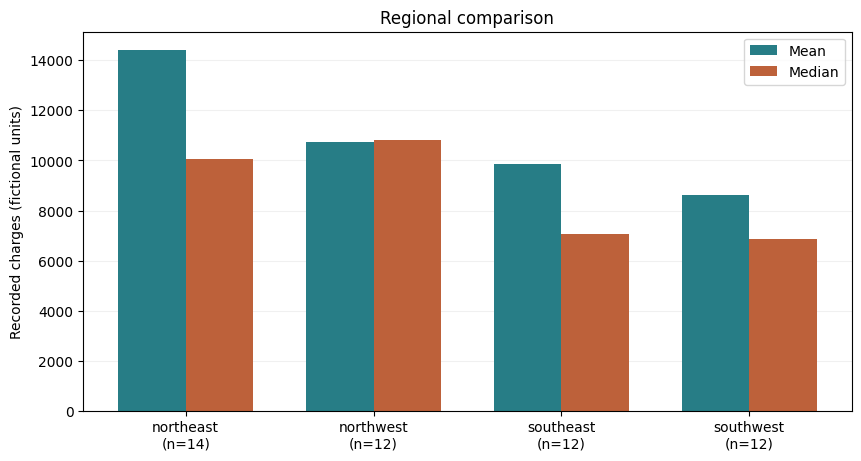

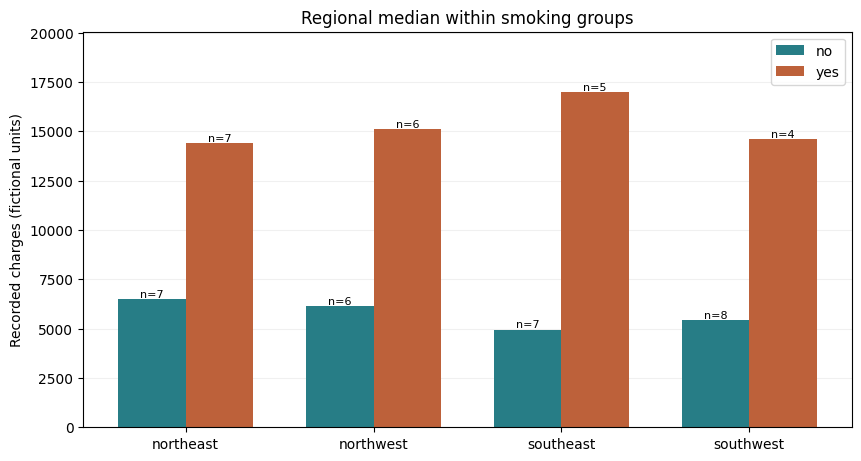

overall: highest regional median = northwest; lowest = southwest; spread = 3,948.56 fictional units
no: highest regional median = northeast; lowest = southeast; spread = 1,548.90 fictional units
yes: highest regional median = southeast; lowest = northeast; spread = 2,598.30 fictional units
Compare ranks and spreads across rows above; different ranks suggest composition may matter, not a causal regional effect.


In [10]:
regional = summary(cleaned, 'region')
composition = (cleaned.assign(smoker_flag=cleaned.smoker.eq('yes').astype(int))
               .groupby('region')['smoker_flag'].mean().rename('smoker_share'))
regional = regional.join(composition, on='region')
strata = summary(cleaned, ['region','smoker'])
display(regional.round(3)); display(strata.round(2))
assert regional.n.sum() == len(cleaned) == strata.n.sum()
assert np.isclose(np.average(regional['mean'], weights=regional.n), cleaned.charges.mean())
for kind in ['region','stratified']:
    chart(cleaned, kind, unit); plt.show()
for label, g in [('overall', regional), *list(strata.groupby('smoker'))]:
    ordered = g.sort_values('median', ascending=False)
    if len(ordered) > 1:
        print(f'{label}: highest regional median = {ordered.iloc[0].region}; '
              f'lowest = {ordered.iloc[-1].region}; spread = {ordered["median"].max()-ordered["median"].min():,.2f} {unit}')
    else:
        print(f'{label}: fewer than two regions, comparison unavailable.')
print('Compare ranks and spreads across rows above; different ranks suggest composition may matter, not a causal regional effect.')

### Sensitivity analysis and independent validation
Matched rows are not proof of repeated individuals. Compare the primary results with a hypothetical dataset excluding exact matches without using that altered dataset for the main results. This measures sensitivity to the chosen retention rule.

In [11]:
alternative = cleaned.drop_duplicates(subset=FIELDS)
comparison = pd.DataFrame({'retained_matches': [len(cleaned), cleaned.charges.mean(), cleaned.charges.median()],
                           'hypothetical_remove_matches': [len(alternative), alternative.charges.mean(), alternative.charges.median()]},
                          index=['n','mean','median'])
display(comparison.round(3))
print('Mean change if matches removed:', round(alternative.charges.mean()-cleaned.charges.mean(), 2))
for group in ['region','smoker',['region','smoker']]:
    s = summary(cleaned, group)
    assert s.n.sum() == len(cleaned)
    assert np.isclose(np.average(s['mean'], weights=s.n), cleaned.charges.mean())
assert filter_data(cleaned, BANDS, list(cleaned.smoker.unique()), list(cleaned.region.unique())).equals(cleaned)
assert filter_data(cleaned, [], list(cleaned.smoker.unique()), list(cleaned.region.unique())).empty
print('PASS: row reconciliation, weighted mean reconciliation, all and empty selections.')

,retained_matches,hypothetical_remove_matches
n,50.000,49.000
mean,11056.182,11033.104
median,8014.455,7916.320


Mean change if matches removed: -23.08
PASS: row reconciliation, weighted mean reconciliation, all and empty selections.


# Criterion 2.2 — Code review and testing

Actual improvements observed during development on the synthetic fixture:

| Issue | Before | After | Validation |
|---|---|---|---|
| Reload lost string dtypes | `pd.read_csv(path, dtype={'age_band': 'string'})` | `pd.read_csv(path, dtype={col: 'string' for col in [*CATEGORIES, 'age_band']})` | `test_roundtrip` initially failed, then checks frame equality and charge totals. |
| Empty rejection set caused an exception | `rejected['reason'] = flags.loc[invalid].apply(..., axis=1)` always executed | only run apply when `invalid.any()`, otherwise initialize an empty Series | `test_age_boundaries` initially failed; revised test exercises all-valid data. |
| Risk of wrong group aggregation | unweighted average of regional means (illustrative anti-pattern, not used in production) | `np.average(s['mean'], weights=s.n)` | `test_group_reconciliation` independently reconciles counts and overall mean. |

Manual review: descriptive functions and docstrings; reusable `summary`, `chart`, `narrative` and `filter_data` prevent notebook/dashboard divergence; explicit data types and schema checks; pathlib makes file paths relative to the project; exceptions provide context. PEP8 review was manual, not an automated linter. Some compact lines exceed 79 characters, so style is not claimed fully compliant. No speed improvement claimed because it was not benchmarked. Tests use fictional input only; see actual console output in `test_results.txt` and run again with your environment. Review Git history after creating repository; suggested commits in README are not proof of actual learner commits.


# Task 3 — AI assistance record (3.1, 3.2)

Tool: OpenAI ChatGPT, used 25 November 2026. It was selected to interpret a lengthy rubric, develop Python/Streamlit code, review ETL decisions and draft evidence-based communication. The learner must review and understand all code and may need to add their own subsequent prompt/response history under institutional rules.

Actual user prompt: “Understand this assignment and provide complete solution so that I can get maximum marks”. Assistant interpreted the brief, selected three business questions, built shared functions, tests, dashboard and notebook, and recommended retaining repeated valid rows and high charges. No confidential records were provided. Dataset acquisition failed; synthetic fixtures were used explicitly for verification. No actual numerical finding has been claimed.

## Validation and review of suggestions
- Accepted: preserve raw data; use count/mean/median, stratify by smoking; test empty dashboard selections and compare summary arithmetic.
- Modified: the initial CSV reload assumed only `age_band` needed an explicit string dtype. The test failed because sex/smoker/region were pandas string fields; revised reload specifies all categorical strings. Roundtrip test now checks types and values.
- Modified: initial exclusion-reason `.apply` ran on an empty DataFrame and failed for all-valid data. Revised branch creates an empty reason Series when no invalid rows exist. Boundary test checks all-valid data.
- Rejected: inventing an official dataset licence or using the fictional test dataset as final evidence; direct download failed. Predictive extension omitted as not necessary and temporal validation impossible.

## AI-assisted narrative — draft and revision
Draft wording (generated during this work, not a separate claimed conversation): “Compare the mean and median charge by smoking status and region. Use the largest differences to identify groups for investigation.”
Revised wording: use `analysis.narrative`, which calculates selected record count, mean, median, smoking difference and regional median directly. It states that observed differences are not causal and cannot be used for individual pricing. One-group and empty selections have separate wording. The notebook displays the exact same narrative as the dashboard for identical selections. `test_filters` checks selection count and edge cases; `test_group_reconciliation` independently verifies group arithmetic. Actual data validation and learner review remain mandatory.

After obtaining the real data, record the actual generated narrative, verify each number against the tables and add date, reviewer and any revisions. Do not claim the learner personally wrote prompts or conducted checks they have not performed. A live AI API is not required and no records are sent to an AI service by the app.


### Verified AI-assisted management narrative (3.2)
The wording below is shared with the Streamlit app. Numerical facts are computed from the validated DataFrame rather than hallucinated by an AI system. Compare the numbers to the outputs immediately above. The learner should retain their own verification record and add any dataset-specific interpretation.

In [12]:
management_text = narrative(cleaned, unit)
display(Markdown(management_text))
assert f'{len(cleaned):,} records' in management_text
assert f'{cleaned.charges.mean():,.2f}' in management_text
assert f'{cleaned.charges.median():,.2f}' in management_text
if {'yes','no'}.issubset(set(cleaned.smoker)):
    difference = (cleaned.loc[cleaned.smoker.eq('yes'), 'charges'].mean()
                  - cleaned.loc[cleaned.smoker.eq('no'), 'charges'].mean())
    assert f'{difference:,.2f}' in management_text
assert 'highest regional median' not in management_text or len(regional) > 1
if len(regional) > 1:
    assert f'{regional["median"].max():,.2f}' in management_text
print('Narrative numerical checks passed for this input.')

This selection contains 50 records. Mean charges are 11,056.18 and median charges are 8,014.45 (fictional units).

Mean recorded charges for smokers (22 records) minus non-smokers (28 records) equal 11,746.48 fictional units. This is an observed difference, not a causal effect.

Age and BMI have Pearson correlations with charges of 0.206 and 0.102, respectively. Review smoking-specific results and scatter plots before interpreting these linear associations.

The highest regional median is northwest (10,799.37); compare within smoking groups before interpreting regional differences.

Within-smoking-group regional median ranges (fictional units) are: no: 1,548.90; yes: 2,598.30. These are unadjusted descriptive contrasts.

Use these summaries for aggregate planning and further investigation, not individual pricing. Dates, clinical history and coverage detail are unavailable in the expected schema.

Narrative numerical checks passed for this input.


## Task 3 — Evaluation (3.3)
**BQ1** can be answered descriptively if both smoking categories exist, but not causally. The box plot and mean/median difference show separation and spread. Age-stratified summaries add context but are not a causal adjustment. **BQ2** can be answered as observed association using scatter plots and group-specific coefficients; a nonlinear relationship may be missed by Pearson's r. Spearman rank correlation is a reasonable alternative for monotonic nonlinear associations, though it loses information about linear scale. **BQ3** can be answered in broad regional categories if multiple groups exist; subgroup comparisons reduce ambiguity from different smoking composition but do not establish adjusted geographic effects. A map would imply more spatial detail than available. The median is robust to unusually high costs while the mean is needed for aggregate planning; neither alone is sufficient. Boxplots give distribution context beyond bars, but bars are easier for nontechnical comparisons.

The source may lack observation dates, clinical diagnoses, treatments, insurer/payment rules, income, geographic detail and sampling design. Without these, representativeness, price levels over time, causal effects and clinical quality are unresolved. Unequal group sizes and small strata can create unstable comparisons. Correlation ignores confounders and prediction does not establish causation. A future project could collect time-stamped claims, policy coverage and utilization with appropriate governance, then compare time-based validation and a simple baseline. AI may generate incorrect logic, unsupported claims or code that runs but yields misleading aggregates; automated tests, independent checks and source verification reduce, but do not eliminate, these risks.

**Management recommendation:** review the groups and regions with large charge differences, verify coverage and clinical drivers, and use these results for sample-based aggregate planning only. Do not infer that changing smoking status would mechanically change charges by the observed mean difference, and do not use individual attributes for automated pricing. Lessons: retain valid extremes, account for group sizes, and use reproducible ETL and shared calculations. Next step: obtain authorized, time-stamped claims and service categories to improve planning validity.

# Task 4 — Data management (4.1, 4.2)

Source: assigned Kaggle Healthcare Insurance dataset, secondary data in CSV format. Download the exact assigned dataset manually; record original filename, date, description, licence/permission, units and coverage in `data/source_metadata.json`. A publicly visible page does not grant redistribution rights. Neither licence nor raw file could be verified by this assistant. Do not guess the currency, year or representativeness. If the source does not confirm a field, explicitly enter 'Not stated by source'. Permission must genuinely be confirmed before deployment.

## Expected data dictionary (confirm against source)
| Field | Type after ETL | Meaning / units | Validation |
|---|---|---|---|
| age | integer | age in years (expected) | integer 18–120, project adult cohort assumption |
| sex | string | recorded category, not inferred gender identity | female/male, expected source categories |
| bmi | float | body mass index, kg/m² (expected) | finite >0; outside 10–80 review only |
| children | integer | covered children/dependants; count | nonnegative integer |
| smoker | string | recorded smoking status | yes/no |
| region | string | broad geographic category | northeast, northwest, southeast, southwest |
| charges | float | recorded medical insurance charges, units from source | finite, nonnegative; IQR extremes retained |
| age_band | string | derived age segment | [18,30), [30,40), [40,50), [50,60), [60,∞) |

## Lineage and quality controls
Source download → unchanged raw CSV and SHA-256 → pandas profile → normalized labels / parsed numeric fields → validation and quarantined rows (with source row and reason) → age band → separate cleaned CSV → reload and equality check → group summaries and dashboard. Report raw, retained and excluded counts. Reject unexpected schema; investigate and fix documented assumptions rather than silently coercing unknown categories. Missing required values are quarantined; if material, compare excluded and included characteristics and request correction. No imputation because replacing target charges invents observed expenditure and replacing attributes risks biased grouping. No encoding needed for exploratory analysis; numeric categories would imply artificial order. Valid extremes remain; use robust summaries. Preserve identical rows because no unique ID, report sensitivity to removing them without changing the primary dataset. Review age/BMI bounds with source documentation; they are analytic flags/rules, not medical diagnostic criteria.

| Dimension | Measurable check / limitation | Action |
|---|---|---|
| Completeness | missing per column, parse failures, complete row rate | record exclusions and review proportion |
| Consistency | allowed category values, normalization count, matching types | standardize whitespace/case; investigate unexpected labels |
| Accuracy | external clinical/billing truth cannot be checked; internal range checks only | request data dictionary and source reconciliation |
| Timeliness | acquisition date recorded; observation period may be unknown | no forecasts or current cost claims without dates |
| Uniqueness | count exact repeated rows, no person identifier | retain and compare sensitivity; request ID if authorized |
| Validity | schema, finite values, allowed categories, plausible project bounds | quarantine failed rows; log reasons; stop if none valid |

CSV is readable, portable, suitable for a small static file and auditable with hashes; it lacks enforced types, constraints, concurrent transactions and row-level permissions. SQLite would offer typed schemas, checks, SQL queries and transactional updates for a growing single-user project; a governed database with access control would be better for multi-user clinical operations. CSV plus explicit code validation is proportionate here. Keep raw separate from derived data; never overwrite it. Do not publish quarantine files; they may include unexpected content. Restrict access to private source copies, keep credentials out of Git, use HTTPS and authorized sharing, and agree retention/deletion periods with the institution. Publish only permitted artifacts. Public data with no direct identifiers may still allow reidentification through combinations; avoid row-level public downloads and consider suppressing small groups for real sensitive data. Do not apply these patterns to individual eligibility, pricing or discrimination. Evaluate representativeness and group fairness before operational use.

HL7 FHIR is an electronic health information exchange standard [3]; it would be relevant for integrating governed clinical/claim resources, not a requirement to convert this static CSV. ICD diagnosis coding would be useful for case-mix adjustment if diagnoses existed; none are expected here. Privacy obligations such as GDPR or HIPAA depend on jurisdiction, entity and identifiability; no blanket claim of compliance is possible. Data minimization and secure sharing remain appropriate regardless.

[3] HL7, FHIR Overview, https://www.hl7.org/fhir/overview.html (accessed 25 November 2026).


## Final completion checklist
- Run this notebook with the assigned CSV, confirm its source metadata and inspect the actual charts; add your own precise interpretation of the BQ1–BQ3 results.
- Verify the recorded findings and the management narrative against the dashboard with the same filters. Add evidence of learner testing and Git history review.
- Confirm permission for repository and cloud sharing; keep raw and quarantine private where necessary. Deploy `app.py` and record both URLs in README.
- Cite the dataset and external sources, acknowledge ChatGPT assistance, and comply with college AI-use rules. No guaranteed marks: the assessor determines achievement.